# Computer Vision Lab 09 – Object Detection
All tasks in one run. Models/data are downloaded inside the notebook; all outputs are saved in `outputs/`.

In [1]:
import importlib, subprocess, sys
chk = subprocess.run([sys.executable,"-c","import cv2;print(hasattr(cv2.dnn,'readNetFromCaffe'))"],capture_output=True,text=True).stdout.strip()
if chk != "True":
    subprocess.run([sys.executable,"-m","pip","uninstall","-y","-q","opencv-python","opencv-contrib-python","opencv-python-headless"])
    subprocess.check_call([sys.executable,"-m","pip","install","-q","opencv-python-headless<5"])
for pkg, mod in [("ultralytics","ultralytics"),("opencv-python-headless","cv2"),("torch","torch"),("torchvision","torchvision"),("matplotlib","matplotlib"),("pandas","pandas")]:
    try: importlib.import_module(mod)
    except ImportError: subprocess.check_call([sys.executable,"-m","pip","install","-q",pkg])

import os, time, math, urllib.request
import cv2, numpy as np, pandas as pd, torch, torchvision
import matplotlib.pyplot as plt
from ultralytics import YOLO

OUT = "outputs"; W = "weights"; D = "data"
for p in (OUT, W, D, f"{OUT}/compare"): os.makedirs(p, exist_ok=True)
torch.set_num_threads(os.cpu_count())

def dl(url, path):
    if not os.path.exists(path): urllib.request.urlretrieve(url, path)
    return path

GH = "https://github.com/ultralytics/assets/releases/download/v8.3.0/"
w_yolov8  = dl(GH+"yolov8n.pt",      f"{W}/yolov8n.pt")
w_yolov3  = dl(GH+"yolov3u.pt",      f"{W}/yolov3u.pt")
w_pose    = dl(GH+"yolo11n-pose.pt", f"{W}/yolo11n-pose.pt")
w_retina  = dl("https://github.com/OlafenwaMoses/ImageAI/releases/download/3.0.0-pretrained/retinanet_resnet50_fpn_coco-eeacb38b.pth", f"{W}/retinanet_resnet50_fpn_coco.pth")
ssd_proto = dl("https://raw.githubusercontent.com/chuanqi305/MobileNet-SSD/master/deploy.prototxt", f"{W}/ssd_deploy.prototxt")
ssd_model = dl("https://raw.githubusercontent.com/chuanqi305/MobileNet-SSD/master/mobilenet_iter_73000.caffemodel", f"{W}/ssd_mobilenet.caffemodel")
video_path = dl("https://github.com/intel-iot-devkit/sample-videos/raw/master/person-bicycle-car-detection.mp4", f"{D}/street.mp4")
print("downloads done")

downloads done


In [2]:
def open_source():
    cap = cv2.VideoCapture(0)
    if cap.isOpened() and cap.read()[0]:
        return cap, "webcam"
    cap.release()
    return cv2.VideoCapture(video_path), "video file (no webcam available)"

def read_frames(n, width=640):
    cap = cv2.VideoCapture(video_path); total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)); frames = []
    for idx in np.linspace(0, total-1, n).astype(int):
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx)); ok, f = cap.read()
        if ok:
            h, w = f.shape[:2]; frames.append(cv2.resize(f, (width, int(h*width/w))))
    cap.release(); return frames

def sample_source(cap, n, total=None):
    total = total or int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    stride = max(total // n, 1) if total > 0 else 1
    i = 0
    while True:
        ok, f = cap.read()
        if not ok: return
        if i % stride == 0: yield f
        i += 1

def draw(img, boxes, names, confs, color=(255,0,255)):
    for (x1,y1,x2,y2), n, c in zip(boxes, names, confs):
        x1,y1,x2,y2 = map(int,(x1,y1,x2,y2))
        cv2.rectangle(img,(x1,y1),(x2,y2),color,2)
        cv2.putText(img,f"{n} {c:.2f}",(x1,max(y1-5,12)),cv2.FONT_HERSHEY_SIMPLEX,0.5,(255,0,0),2)
    return img

def show(imgs, titles, cols=2, size=(7,5)):
    rows = math.ceil(len(imgs)/cols)
    plt.figure(figsize=(size[0]*cols, size[1]*rows))
    for i,(im,t) in enumerate(zip(imgs,titles)):
        plt.subplot(rows,cols,i+1); plt.imshow(cv2.cvtColor(im,cv2.COLOR_BGR2RGB)); plt.title(t); plt.axis("off")
    plt.tight_layout(); plt.show()

def write_video(frames, path, fps=10):
    h,w = frames[0].shape[:2]
    vw = cv2.VideoWriter(path, cv2.VideoWriter_fourcc(*"mp4v"), fps, (w,h))
    for f in frames: vw.write(f)
    vw.release()

## Task 1 – YOLO on live webcam feed (lab assets)

Source: video file (no webcam available)


[ WARN:0@2.909] global cap_v4l.cpp:914 open VIDEOIO(V4L2:/dev/video0): can't open camera by index
[ WARN:0@2.910] global cap_ffmpeg_impl.hpp:1246 open VIDEOIO/FFMPEG: OpenCV should be configured with libavdevice to open a camera device


Detections per class: {'person': 29, 'sports ball': 1, 'cell phone': 2, 'car': 12, 'kite': 1, 'bicycle': 8, 'boat': 1}


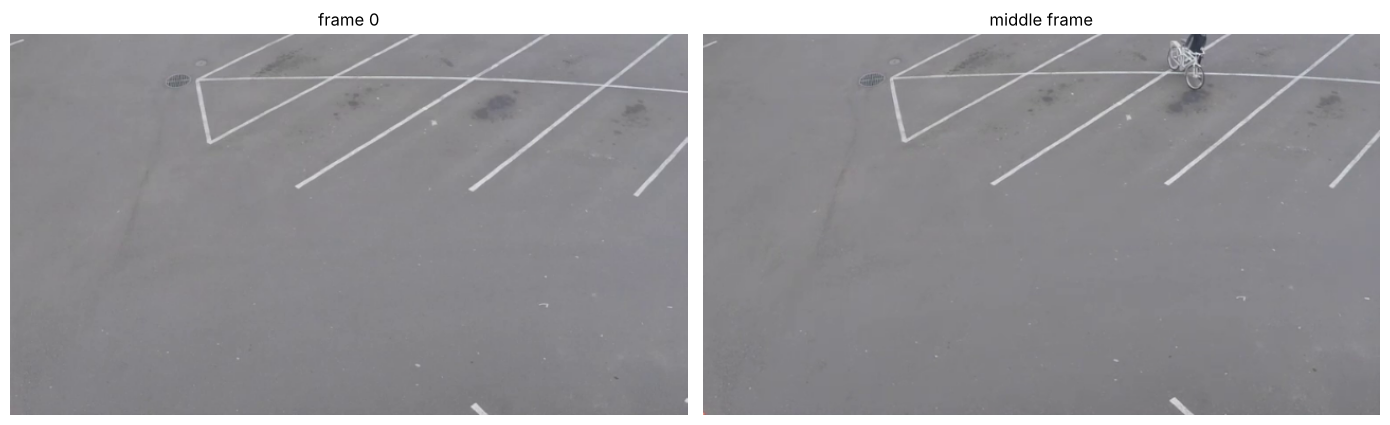

In [3]:
yolo8 = YOLO(w_yolov8)
cap, src = open_source(); print("Source:", src)
out_frames, counts = [], {}
for f in sample_source(cap, 90):
    if len(out_frames) >= 90: break
    f = cv2.resize(f, (640, int(f.shape[0]*640/f.shape[1])))
    r = yolo8(f, verbose=False, device="cpu")[0]
    names = [yolo8.names[int(c)] for c in r.boxes.cls]
    draw(f, r.boxes.xyxy.tolist(), names, r.boxes.conf.tolist())
    for n in names: counts[n] = counts.get(n,0)+1
    out_frames.append(f)
cap.release()
write_video(out_frames, f"{OUT}/task1_yolov8_detection.mp4")
cv2.imwrite(f"{OUT}/task1_yolov8_sample.jpg", out_frames[len(out_frames)//2])
print("Detections per class:", counts)
show([out_frames[0], out_frames[len(out_frames)//2]], ["frame 0","middle frame"])

## Task 1 (manual) – Car detection on street video

max cars in a frame: 1 | avg: 0.15


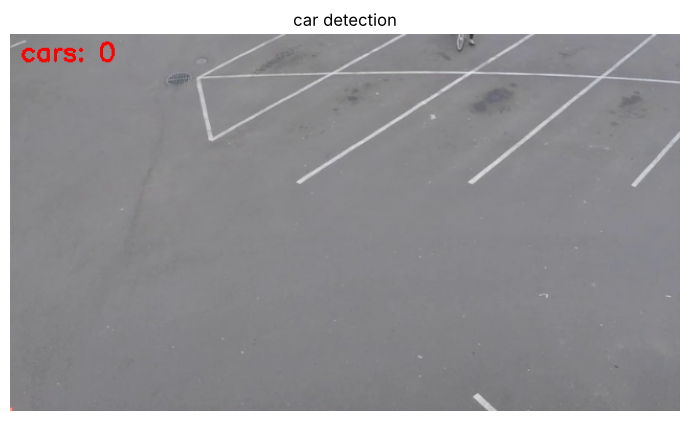

In [4]:
car_frames, car_counts = [], []
cap = cv2.VideoCapture(video_path)
for f in sample_source(cap, 60):
    if len(car_frames) >= 60: break
    f = cv2.resize(f, (640, int(f.shape[0]*640/f.shape[1])))
    r = yolo8(f, classes=[2], verbose=False, device="cpu")[0]
    draw(f, r.boxes.xyxy.tolist(), ["car"]*len(r.boxes), r.boxes.conf.tolist(), (0,255,0))
    cv2.putText(f, f"cars: {len(r.boxes)}", (10,25), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0,0,255), 2)
    car_frames.append(f); car_counts.append(len(r.boxes))
cap.release()
write_video(car_frames, f"{OUT}/task1_car_detection.mp4")
cv2.imwrite(f"{OUT}/task1_car_detection_sample.jpg", car_frames[len(car_frames)//2])
print("max cars in a frame:", max(car_counts), "| avg:", round(np.mean(car_counts),2))
show([car_frames[len(car_frames)//2]], ["car detection"], cols=1)

## Task 2 – YOLOv3, SSD, RetinaNet on common frames

20 common frames (360, 640, 3)


YOLOv3 done


SSD (MobileNet) done


RetinaNet done


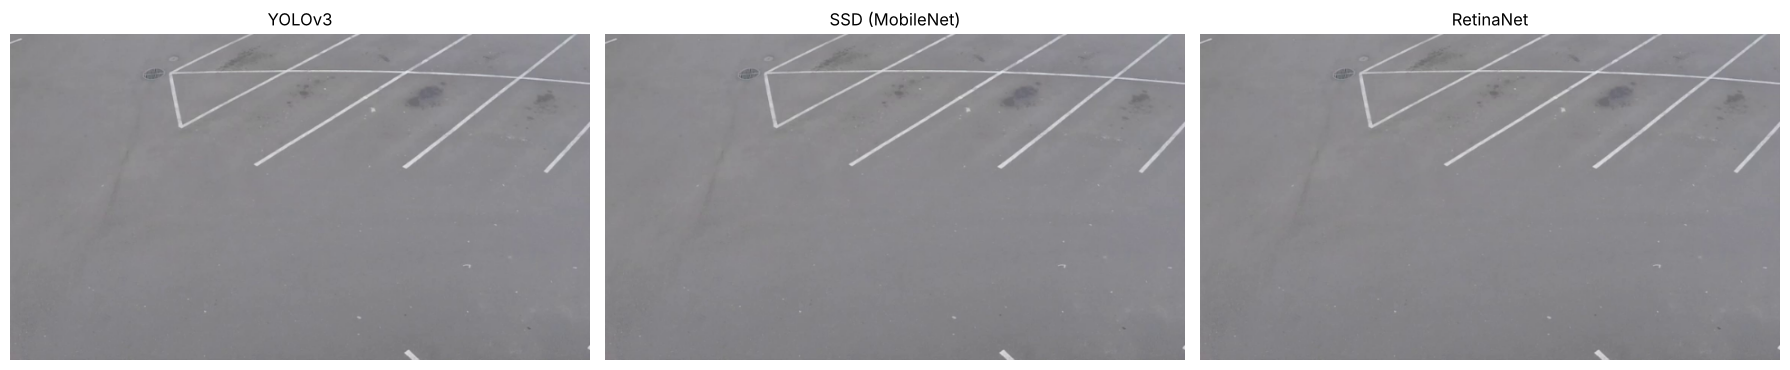

In [5]:
frames = read_frames(n=20)
print(len(frames), "common frames", frames[0].shape)
CONF = 0.25
results = {}

class Y3:
    name = "YOLOv3"; path = w_yolov3
    def __init__(s): s.m = YOLO(w_yolov3)
    def __call__(s, f):
        r = s.m(f, conf=CONF, verbose=False, device="cpu")[0]
        return r.boxes.xyxy.tolist(), [s.m.names[int(c)] for c in r.boxes.cls], r.boxes.conf.tolist()

VOC = ["background","aeroplane","bicycle","bird","boat","bottle","bus","car","cat","chair","cow","diningtable","dog","horse","motorbike","person","pottedplant","sheep","sofa","train","tvmonitor"]
class SSD:
    name = "SSD (MobileNet)"; path = ssd_model
    def __init__(s): s.net = cv2.dnn.readNetFromCaffe(ssd_proto, ssd_model)
    def __call__(s, f):
        h,w = f.shape[:2]
        s.net.setInput(cv2.dnn.blobFromImage(f, 0.007843, (300,300), 127.5))
        d = s.net.forward()[0,0]; B,N,C = [],[],[]
        for x in d:
            if x[2] >= CONF:
                B.append([x[3]*w,x[4]*h,x[5]*w,x[6]*h]); N.append(VOC[int(x[1])]); C.append(float(x[2]))
        return B,N,C

from torchvision.models.detection import retinanet_resnet50_fpn, RetinaNet_ResNet50_FPN_Weights
class Retina:
    name = "RetinaNet"; path = w_retina
    def __init__(s):
        s.m = retinanet_resnet50_fpn(weights=None, weights_backbone=None, min_size=480, max_size=640, score_thresh=CONF)
        s.m.load_state_dict(torch.load(w_retina, map_location="cpu")); s.m.eval()
        s.cats = RetinaNet_ResNet50_FPN_Weights.COCO_V1.meta["categories"]
    def __call__(s, f):
        t = torch.from_numpy(cv2.cvtColor(f, cv2.COLOR_BGR2RGB)).permute(2,0,1).float()/255
        with torch.no_grad(): o = s.m([t])[0]
        return o["boxes"].tolist(), [s.cats[int(l)] for l in o["labels"]], o["scores"].tolist()

rows, dets, samples = [], [], {}
for cls in (Y3, SSD, Retina):
    det = cls(); det(frames[0])
    times = []
    for i,f in enumerate(frames):
        t0 = time.perf_counter(); B,N,C = det(f); times.append(time.perf_counter()-t0)
        for b,n,c in zip(B,N,C):
            dets.append(dict(model=det.name, frame=i, cls=n, conf=c, area=(b[2]-b[0])*(b[3]-b[1])))
        if i == 0: samples[det.name] = draw(f.copy(), B, N, C)
    ms = np.mean(times)*1000
    rows.append(dict(model=det.name, size_MB=round(os.path.getsize(det.path)/1e6,1), inference_ms=round(ms,1), FPS=round(1000/ms,2)))
    cv2.imwrite(f"{OUT}/compare/{det.name.split()[0].lower()}_frame0.jpg", samples[det.name])
    print(det.name, "done")

dets = pd.DataFrame(dets)
show(list(samples.values()), list(samples.keys()), cols=3, size=(6,4))

## Task 3 – Measurements

,size_MB,inference_ms,FPS,detections,mean_conf
model,,,,,
YOLOv3,207.9,1210.2,0.83,12,0.803
SSD (MobileNet),23.3,56.2,17.79,4,0.755
RetinaNet,136.6,964.4,1.04,21,0.522


model,RetinaNet,SSD (MobileNet),YOLOv3
cls,,,
bicycle,0.496,NaN,0.695
bus,0.390,NaN,NaN
car,0.701,0.921,0.927
cell phone,0.425,NaN,NaN
person,0.521,0.255,0.795


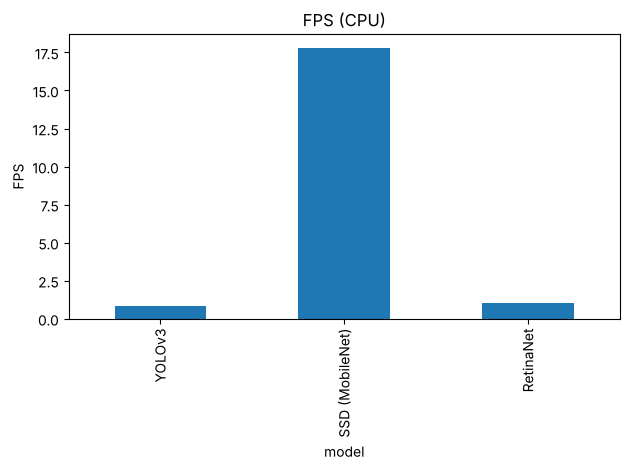

In [6]:
speed = pd.DataFrame(rows).set_index("model")
conf_summary = dets.groupby("model").conf.agg(detections="count", mean_conf="mean").round(3)
speed = speed.join(conf_summary)
speed.to_csv(f"{OUT}/model_comparison.csv"); display(speed)

per_class = dets.pivot_table(index="cls", columns="model", values="conf", aggfunc="mean").round(3)
per_class.to_csv(f"{OUT}/confidence_per_class.csv"); display(per_class)

ax = speed[["FPS"]].plot.bar(legend=False, title="FPS (CPU)"); plt.ylabel("FPS"); plt.tight_layout()
plt.savefig(f"{OUT}/fps_comparison.png"); plt.show()

## Task 4 – Discussion

In [7]:
small = dets[dets.area < 32*32].groupby("model").agg(small_dets=("conf","count"), small_mean_conf=("conf","mean")).round(3)
display(small)
fast = speed.FPS.idxmax(); light = speed.size_MB.idxmin()
sm = small.small_dets.idxmax() if len(small) else "n/a"
conf_best = speed.mean_conf.idxmax()
txt = f"""Real-time detection      : {fast} ({speed.FPS.max()} FPS on CPU)
Small object recognition : {sm} (most detections with box area < 32x32 px); highest mean confidence overall: {conf_best}
Resource-limited / CPU   : {light} (smallest model, {speed.size_MB.min()} MB) and {fast} (fastest)"""
print(txt); open(f"{OUT}/discussion.txt","w").write(txt)

,small_dets,small_mean_conf
model,,
RetinaNet,5,0.397
YOLOv3,2,0.549


Real-time detection      : SSD (MobileNet) (17.79 FPS on CPU)
Small object recognition : RetinaNet (most detections with box area < 32x32 px); highest mean confidence overall: YOLOv3
Resource-limited / CPU   : SSD (MobileNet) (smallest model, 23.3 MB) and SSD (MobileNet) (fastest)


281

## Task 5 – Real-time pose estimation (webcam feed)

Source: video file (no webcam available)


[ WARN:0@63.824] global cap_v4l.cpp:914 open VIDEOIO(V4L2:/dev/video0): can't open camera by index


,frame,person,left_elbow_angle,right_elbow_angle,nose_x,nose_y
0,3,0,155.0,105.8,468.3,304.7
1,4,0,158.4,116.9,473.2,260.9
2,5,0,176.2,103.8,485.6,225.6
3,6,0,178.4,134.6,502.0,198.0
4,7,0,179.3,139.6,524.5,175.9
5,8,0,167.8,134.0,551.5,155.9
6,9,0,179.3,130.3,580.2,137.2
7,10,0,179.9,120.7,605.6,122.5
8,12,0,167.8,149.9,640.0,90.7
9,81,0,160.8,135.3,493.1,48.8


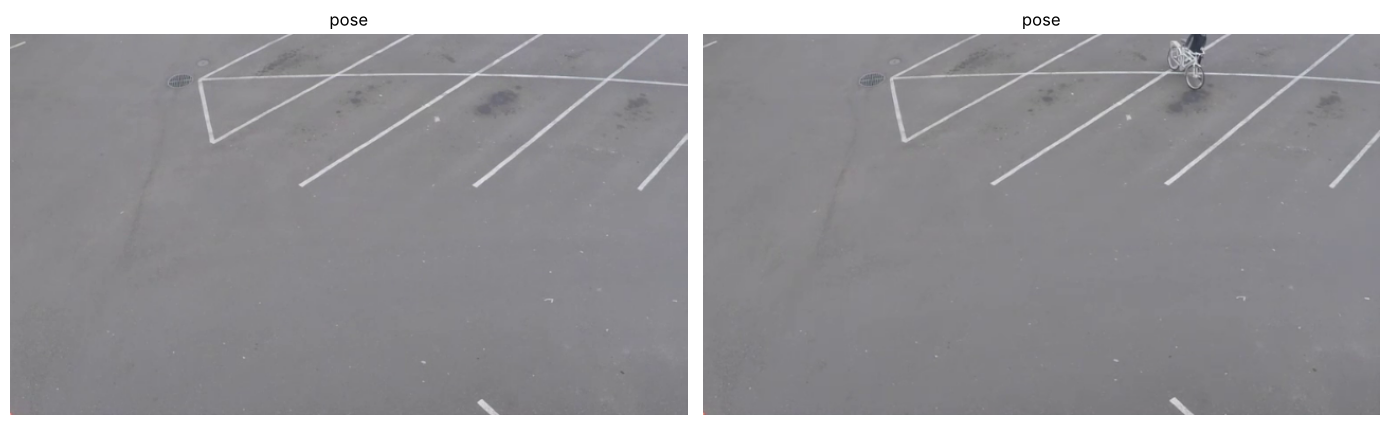

In [8]:
pose = YOLO(w_pose)
EDGES = [(5,7),(7,9),(6,8),(8,10),(5,6),(5,11),(6,12),(11,12),(11,13),(13,15),(12,14),(14,16),(0,5),(0,6)]
def angle(a,b,c):
    a,b,c = map(np.array,(a,b,c)); v1,v2 = a-b, c-b
    return float(np.degrees(np.arccos(np.clip(np.dot(v1,v2)/(np.linalg.norm(v1)*np.linalg.norm(v2)+1e-9),-1,1))))

cap, src = open_source(); print("Source:", src)
pose_frames, log = [], []
for f in sample_source(cap, 90):
    if len(pose_frames) >= 90: break
    f = cv2.resize(f, (640, int(f.shape[0]*640/f.shape[1])))
    r = pose(f, verbose=False, device="cpu")[0]
    if r.keypoints is not None:
        for pi, kp in enumerate(r.keypoints.xy.tolist()):
            if sum(1 for p in kp if p[0] > 0) < 10: continue
            for a,b in EDGES:
                if kp[a][0] > 0 and kp[b][0] > 0: cv2.line(f, tuple(map(int,kp[a])), tuple(map(int,kp[b])), (0,255,0), 2)
            for p in kp:
                if p[0] > 0: cv2.circle(f, tuple(map(int,p)), 4, (0,0,255), -1)
            row = dict(frame=len(pose_frames), person=pi)
            for side,(s,e,w) in {"left":(5,7,9),"right":(6,8,10)}.items():
                if kp[s][0] > 0 and kp[e][0] > 0 and kp[w][0] > 0:
                    ang = angle(kp[s],kp[e],kp[w]); row[f"{side}_elbow_angle"] = round(ang,1)
                    cv2.putText(f, f"{ang:.0f}", tuple(map(int,kp[e])), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255,255,0), 2)
            for k,name in enumerate(["nose","l_eye","r_eye","l_ear","r_ear","l_shoulder","r_shoulder","l_elbow","r_elbow","l_wrist","r_wrist","l_hip","r_hip","l_knee","r_knee","l_ankle","r_ankle"]):
                row[name+"_x"], row[name+"_y"] = round(kp[k][0],1), round(kp[k][1],1)
            log.append(row)
    pose_frames.append(f)
cap.release()
write_video(pose_frames, f"{OUT}/task5_pose_estimation.mp4")
cv2.imwrite(f"{OUT}/task5_pose_sample.jpg", pose_frames[len(pose_frames)//2])
pd.DataFrame(log).to_csv(f"{OUT}/task5_pose_coordinates.csv", index=False)
display(pd.DataFrame(log).head(10)[["frame","person","left_elbow_angle","right_elbow_angle","nose_x","nose_y"]])
show([pose_frames[len(pose_frames)//4], pose_frames[len(pose_frames)//2]], ["pose","pose"])

In [9]:
print(sorted(os.listdir(OUT)), sorted(os.listdir(f"{OUT}/compare")))

['compare', 'confidence_per_class.csv', 'discussion.txt', 'fps_comparison.png', 'model_comparison.csv', 'task1_car_detection.mp4', 'task1_car_detection_sample.jpg', 'task1_yolov8_detection.mp4', 'task1_yolov8_sample.jpg', 'task5_pose_coordinates.csv', 'task5_pose_estimation.mp4', 'task5_pose_sample.jpg'] ['retinanet_frame0.jpg', 'ssd_frame0.jpg', 'yolov3_frame0.jpg']
